In [239]:
import torch
import numpy as np

data = torch.tensor([[1, 2, 3], [4, 5, 6], [7, 8, 9]])

weight = torch.randn(1, data.size(dim=1))

net_matrix = data * weight

print(net_matrix)

z = net_matrix.sum(dim=1, keepdim=True)

prediction = np.where(z.sigmoid().numpy() >= 0.5, 1, 0)

print(f'{prediction}')

tensor([[ 0.6454,  2.4126, -2.0513],
        [ 2.5817,  6.0314, -4.1027],
        [ 4.5180,  9.6502, -6.1540]])
[[1]
 [1]
 [1]]


In [240]:
import pandas as pd

df = pd.DataFrame({
    "Assignment 1": [80, 90, 100],
    "Assignment 2": [60, 70, 80],
    "Assignment 3": [70, 80, 90]
}, index=['Student 1: ', 'Student 2: ', 'Student 3:'])

data = torch.tensor(df.to_numpy(), dtype=float)
df['Mean (dim = 1)'] = data.mean(dim=1)



print(df)
print(f"Mean (dim = 0): {data.mean(dim=0).tolist()}")

             Assignment 1  Assignment 2  Assignment 3  Mean (dim = 1)
Student 1:             80            60            70            70.0
Student 2:             90            70            80            80.0
Student 3:            100            80            90            90.0
Mean (dim = 0): [90.0, 70.0, 80.0]


In [241]:

#simulate data
torch.manual_seed(1)
size = (5, 5)
data = torch.randn(size, dtype=float, requires_grad=True)

# make y and array of one column and num of rows from the data between 1 and 0
y = torch.randint(low=0, high=2, size=(size[0], 1))
w = torch.randn((1, size[1]), dtype=float ,requires_grad=True)
b = torch.randn(1, dtype=float, requires_grad=True)
losses = []
#hyper
epochs = 10
lr = 0.001

print('Losses: ')
for epoch in range(epochs):
    #forward pass
    prediction = torch.sigmoid(data @ w.T + b)

    #get loss
    eps = 1e-15
    p_clipped = torch.clamp(prediction, eps, 1 - eps)
    loss = -(y * torch.log(p_clipped) + (1 - y) * torch.log(1 - p_clipped)).mean()

    #backwards pass
    #sets gradients
    loss.backward()

    #update parameters
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad
    #reset gradients to zero
    w.grad.zero_()
    b.grad.zero_()

    #loss list update
    losses.append(loss.item())
    print(loss.item())





Losses: 
0.6986114436646129
0.6983226188915873
0.6980338551868053
0.6977451526063494
0.6974565112063311
0.6971679310428881
0.6968794121721853
0.6965909546504153
0.6963025585338001
0.6960142238785865


In [242]:

#simulate data
torch.manual_seed(1)
size = (5, 5)
data = torch.randn(size, dtype=torch.float32, requires_grad=True)

# make y and array of one column and num of rows from the data between 1 and 0
y = torch.randint(low=0, high=2, size=(size[0], 1))
w = torch.randn((1, size[1]), dtype=torch.float32 ,requires_grad=True)
b = torch.randn(1, dtype=torch.float32, requires_grad=True)
losses = []
#hyper
epochs = 10
lr = 0.001

linear_layer = torch.nn.Linear(size[1], y.size(1))
optimizer = torch.optim.SGD(linear_layer.parameters(), lr)

print('Losses: ')
for epoch in range(epochs):
    
    #forward pass
    # make in out to the num of columns we have and the columns we want at the end
    prediction = torch.sigmoid(linear_layer(data))

    #get loss
    eps = 1e-15
    p_clipped = torch.clamp(prediction, eps, 1 - eps)
    loss = -(y * torch.log(p_clipped) + (1 - y) * torch.log(1 - p_clipped)).mean()

    #backwards pass
    #sets gradients
    loss.backward()

    #update parameters
    optimizer.step()

    #loss list update
    losses.append(loss.item())
    print(loss.item())





Losses: 
0.4774130880832672
0.4771391749382019
0.47659221291542053
0.4757728576660156
0.47468310594558716
0.4733250141143799
0.47170114517211914
0.46981483697891235
0.46766990423202515
0.465270459651947


In [243]:


#logistic regression
class LogisticRegression(torch.nn.Module):
    def __init__(self, columns_in, columns_out, lr=0.01, epochs=100):

        super().__init__()

        self.linear_layer = torch.nn.Linear(columns_in, columns_out)
        self.sigmoid_layer = torch.nn.Sigmoid()

        self.linear_layer.reset_parameters()

        self.optimizer = torch.optim.Adam(self.parameters(), lr=lr)

        self.loss_func = torch.nn.BCELoss()

        #hyper
        self.lr = lr
        self.epochs = epochs

        #loss array
        self.loss_array = []

    def forward_pass(self, x):

        z = self.linear_layer(x)
        #this is basically doing this:
        #z = x @ linear_layer.weight.T + linear_layer.bias

        #sigmoid the scores
        return self.sigmoid_layer(z)

    def Train(self, x, y):
        self.loss_array = []
        for epoch in range(self.epochs):
            #predict
            y_hat = self.forward_pass(x)
                
            #get loss to array
            loss = self.loss_func(y_hat, y)
            self.loss_array.append(loss.item())

            #reset gradients
            self.optimizer.zero_grad()

            #calculate gradients via require_grad graph
            loss.backward()

            #gradient step
            self.optimizer.step()


#simulate data
torch.manual_seed(1)

size = (5, 5)
data = torch.randn(size, dtype=torch.float32, requires_grad=True)
# make y and array of one column and num of rows from the data between 1 and 0
y = torch.randint(low=0, high=2, size=(size[0], 1), dtype=torch.float32)

#hyper
lr = 0.01
epochs = 1000

#model
model = LogisticRegression(size[1], y.shape[1], lr, epochs)
#train
model.Train(data, y)

print(f'Model: \n\n{model}\n')
print(f'Lowest Loss: {min(model.loss_array)}\n')
print(f'Final Loss: {model.loss_array[-1]}\n')



Model: 

LogisticRegression(
  (linear_layer): Linear(in_features=5, out_features=1, bias=True)
  (sigmoid_layer): Sigmoid()
  (loss_func): BCELoss()
)

Lowest Loss: 0.011477085761725903

Final Loss: 0.011477085761725903



In [244]:
class LinearRegression(torch.nn.Module):
    def __init__(self, data_size, out_size=1, lr=0.01, epochs=100):
        super().__init__()
        self.data_size = data_size
        self.out_size = out_size
        self.lr = lr
        self.epochs = epochs

        self.linear_layer = torch.nn.Linear(data_size[1], out_size)
        self.loss_fn = torch.nn.MSELoss(reduction='mean')
        self.optimizer = torch.optim.Adam(self.parameters(), lr)

        self.loss_array = []

        self.y_mean = None
        self.y_std = None
        self.x_mean = None
        self.x_std = None

    def forward(self, X):
        return self.linear_layer(X).flatten()
    
    def fit(self, X, y):
        #scale data
        self.x_mean, self.y_mean = X.mean(dim=0, keepdim=True), y.mean()
        self.x_std, self.y_std = X.std(dim=0, keepdim=True), y.std()

        scaled_x = (X - self.x_mean) / self.x_std
        scaled_y = (y - self.y_mean) / self.y_std

        #reset loss array
        self.loss_array = []

        #training loop
        for epoch in range(self.epochs):
            #reset weights
            self.optimizer.zero_grad()

            #predict
            y_hat = self(scaled_x)

            #get loss
            loss = self.loss_fn(y_hat, scaled_y)
            self.loss_array.append(loss.item())
            
            #calculate gradients
            loss.backward()

            #step grads
            self.optimizer.step()
        return
    def predict(self, x):
        #scale new data
        scaled_x = (x - self.x_mean) / self.x_std

        #receive scaled predictions
        scaled_y_hat = self(scaled_x)

        #unscale predictions to normal state
        unscaled_y_hat = (scaled_y_hat * self.y_std) + self.y_mean

        return unscaled_y_hat

#simulate data

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

houses = fetch_openml(name='houses', version=1, as_frame=True)

df = houses.frame
data = torch.tensor(df.drop(columns=['median_house_value']).to_numpy(), dtype=torch.float32)
y = torch.tensor(df['median_house_value'].to_numpy(), dtype=torch.float32)

train_x, val_x, train_y, val_y = train_test_split(data, y, test_size=0.2)

size = train_x.shape

lin_reg = LinearRegression(size, 1, 0.0001, 10000)
lin_reg.fit(train_x, train_y)
predictions = lin_reg.predict(val_x).detach()


print(predictions, val_y)
print(min(lin_reg.loss_array))




tensor([ 73463.8438, 171274.0625, 182457.7969,  ..., 352280.5312,
        115960.9844,  97134.5781]) tensor([ 80400., 132600., 137900.,  ..., 500001.,  92600., 138500.])
0.3665766417980194


Eval(by ai not by me)

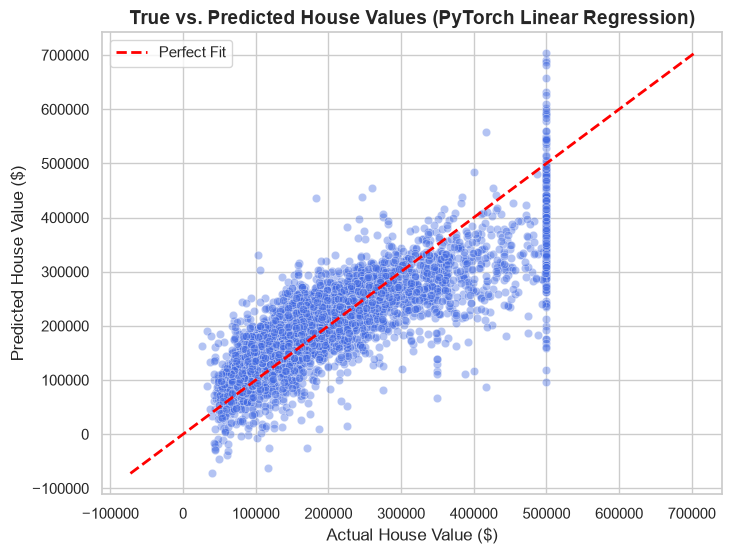

In [245]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure tensors are converted to flat NumPy arrays for plotting
actuals = val_y.detach().numpy()
preds = predictions.detach().numpy()

# Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

# Create the scatter plot with some transparency (alpha) to see overlapping points
sns.scatterplot(x=actuals, y=preds, alpha=0.4, color="royalblue")

# Draw the ideal 45-degree diagonal line (perfect predictions)
min_val = min(actuals.min(), preds.min())
max_val = max(actuals.max(), preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label="Perfect Fit")

# Add labels and title
plt.xlabel("Actual House Value ($)", fontsize=12)
plt.ylabel("Predicted House Value ($)", fontsize=12)
plt.title("True vs. Predicted House Values (PyTorch Linear Regression)", fontsize=14, weight="bold")
plt.legend()
plt.show()

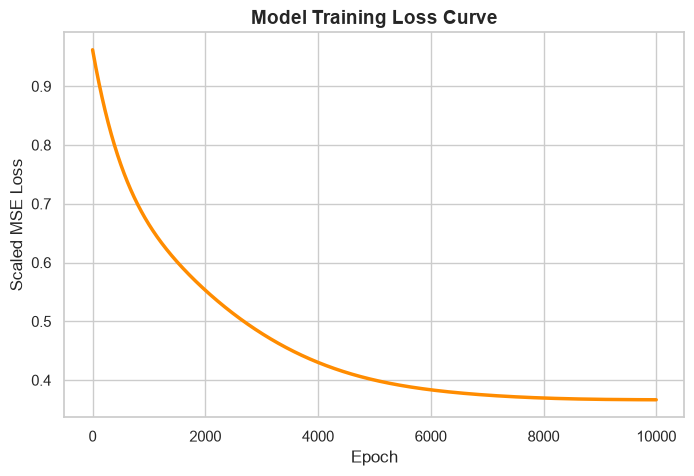

In [246]:
plt.figure(figsize=(8, 5))

# Plot training loss over epochs
sns.lineplot(x=range(len(lin_reg.loss_array)), y=lin_reg.loss_array, color="darkorange", linewidth=2.5)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Scaled MSE Loss", fontsize=12)
plt.title("Model Training Loss Curve", fontsize=14, weight="bold")
plt.show()

In [247]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def evaluate_binary_classifier(model, X_val, y_val):
    """
    Evaluates a trained PyTorch Binary MLP model and visualizes performance.
    """
    # 1. Get predictions from the model (returns 0 or 1 tensor)
    preds = model.predict(X_val)
    
    # Convert PyTorch tensors to NumPy arrays for scikit-learn metrics
    if hasattr(preds, 'numpy'):
        y_pred = preds.numpy().flatten()
    else:
        y_pred = preds.flatten()
        
    if hasattr(y_val, 'numpy'):
        y_true = y_val.numpy().flatten()
    else:
        y_true = y_val.flatten()
        
    # 2. Calculate Key Metrics
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    
    print("=" * 40)
    print(f"Validation Accuracy: {acc * 100:.2f}%")
    print("=" * 40)
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    # 3. Visualize Loss Curve and Confusion Matrix
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot A: Training Loss Curve
    sns.lineplot(
        x=range(len(model.loss_array)), 
        y=model.loss_array, 
        ax=axes[0], 
        color="purple", 
        linewidth=2
    )
    axes[0].set_title("Training Loss Curve (BCELoss)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    
    # Plot B: Confusion Matrix Heatmap
    sns.heatmap(
        cm, 
        annot=True, 
        fmt="d", 
        cmap="Blues", 
        ax=axes[1], 
        cbar=False,
        annot_kws={"size": 14, "weight": "bold"}
    )
    axes[1].set_title("Validation Confusion Matrix", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Predicted Label")
    axes[1].set_ylabel("True Label")
    
    plt.tight_layout()
    plt.show()

# --- How to use it in your script ---
# evaluate_binary_classifier(model, tensor_val_x, tensor_val_y)

In [248]:
class MLP(torch.nn.Module):
    def __init__(self, in_features, hidden_size, out_features, epochs=100, lr=0.01):
        super().__init__()
        #variables
        self.in_features = in_features
        self.hidden_size = hidden_size
        self.out_features = out_features
        self.lr = lr
        self.epochs = epochs
        #make the first layer for each neutron
        self.in_layer = torch.nn.Linear(in_features, hidden_size)
        #activation func
        self.relu = torch.nn.ReLU()
        #loss func
        self.mse = torch.nn.MSELoss()
        #output layer
        self.out_layer = torch.nn.Linear(hidden_size, out_features)

        self.optim = torch.optim.Adam(self.parameters(), lr)
        self.loss_array = []

    def forward(self, x):
        #net input
        z = self.in_layer(x)
        #activate
        a = self.relu(z)
        #out layer
        return self.out_layer(a)
    def fit(self, x, y):
        self.loss_array = []
        for epoch in range(self.epochs):

            y_hat = self.forward(x)
            loss = self.mse(y_hat, y)
            self.loss_array.append(loss.item())
            self.optim.zero_grad()
            loss.backward()
            self.optim.step()

        


Training Complete! Final Loss: 0.0473


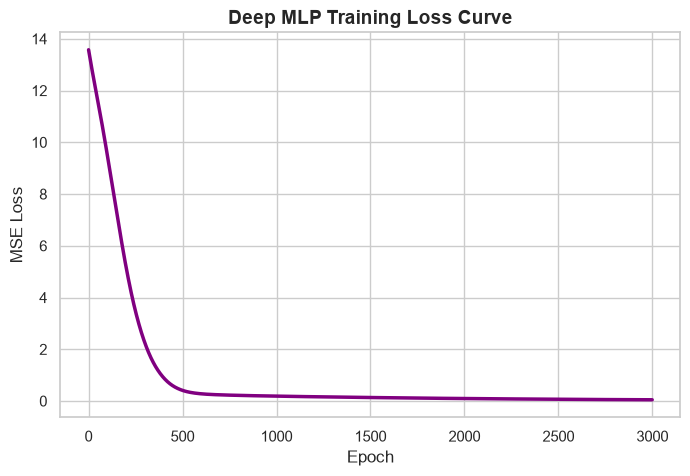

In [249]:
torch.manual_seed(42)
# 500 samples, 4 features each
X = torch.randn(500, 5)

#create nonlinear relation with x to y
y = (X[:, 0] * 1.5) + (X[:, 1] ** 2) - X[:, 3] + (X[:, 4] * 2.5) + (torch.randn(500) * 0.15)
y = y.unsqueeze(1) # Reshape from [500] to [500, 1]

# --- 2. Initialize and Train the MLP ---
# 5 input features -> 25 hidden neurons -> 1 output value
model = MLP(in_features=5, hidden_size=25, out_features=1, epochs=3000, lr=0.001)
model.fit(X, y)

print(f"Training Complete! Final Loss: {model.loss_array[-1]:.4f}")

# --- 3. Visualize Training Loss with Seaborn ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.lineplot(x=range(len(model.loss_array)), y=model.loss_array, color="purple", linewidth=2.5)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("MSE Loss", fontsize=12)
plt.title("Deep MLP Training Loss Curve", fontsize=14, weight="bold")
plt.show()

In [ ]:
class MLPForBC(torch.nn.Module):
    def __init__(self, in_features, hidden_size, out_features=1, epochs=100, lr=0.01):
        super().__init__()
        #variables
        self.in_features = in_features
        self.hidden_size = hidden_size
        self.out_features = out_features
        self.lr = lr
        self.epochs = epochs
        #make the first layer for each neutron
        self.in_layer = torch.nn.Linear(in_features, hidden_size)
        #activation func
        self.relu = torch.nn.ReLU()
        #loss func
        self.mse = torch.nn.BCELoss()
        #output layer
        self.out_layer = torch.nn.Linear(hidden_size, out_features)
        #sigmoid layer
        self.sigmoid_layer = torch.nn.Sigmoid()

        self.optim = torch.optim.Adam(self.parameters(), lr)
        self.loss_array = []


    def forward(self, x):
        #net input
        z = self.in_layer(x)
        #activate
        a = self.relu(z)
        #out layer
        out = self.out_layer(a)
        #final probs
        return self.sigmoid_layer(out)
    
    def predict(self, x):
        self.eval()
        with torch.no_grad():
            scaled_x = self.scale(x)
            p = self.forward(scaled_x)
            return np.where(p >= 0.5, 1, 0)
    
    def fit(self, x, y):
        self.scaled_x = self.scale(x)

        self.loss_array = []
        for epoch in range(self.epochs):

            y_hat = self.forward(self.scaled_x)
            loss = self.mse(y_hat, y)
            self.loss_array.append(loss.item())
            self.optim.zero_grad()
            loss.backward()
            self.optim.step()

    def scale(self, matrix):
        mean = matrix.mean(dim=0)
        std = matrix.std(dim=0)
        return (matrix - mean) / std

        


tensor([[-0.3683, -0.5333,  0.3293,  ...,  1.1736, -0.5011, -0.1958],
        [-0.5534,  0.2670,  0.1742,  ..., -0.4858,  0.2622,  0.1002],
        [ 0.4802, -0.3771, -0.8219,  ...,  0.3928, -0.3667, -0.2903],
        ...,
        [ 0.3228,  0.1691, -0.4696,  ..., -0.1518, -0.2862,  0.1910],
        [-0.9872,  1.0563,  2.6863,  ...,  0.1398,  0.9610, -1.5127],
        [-1.1128,  0.3577, -0.1231,  ...,  0.5585, -0.6363,  2.1332]],
       grad_fn=<AddmmBackward0>)
tensor([[0.0000, 0.0000, 0.3293,  ..., 1.1736, 0.0000, 0.0000],
        [0.0000, 0.2670, 0.1742,  ..., 0.0000, 0.2622, 0.1002],
        [0.4802, 0.0000, 0.0000,  ..., 0.3928, 0.0000, 0.0000],
        ...,
        [0.3228, 0.1691, 0.0000,  ..., 0.0000, 0.0000, 0.1910],
        [0.0000, 1.0563, 2.6863,  ..., 0.1398, 0.9610, 0.0000],
        [0.0000, 0.3577, 0.0000,  ..., 0.5585, 0.0000, 2.1332]],
       grad_fn=<ReluBackward0>)
tensor([[-0.3505, -0.5512,  0.3492,  ...,  1.1891, -0.4856, -0.2127],
        [-0.5541,  0.2754,  0.167

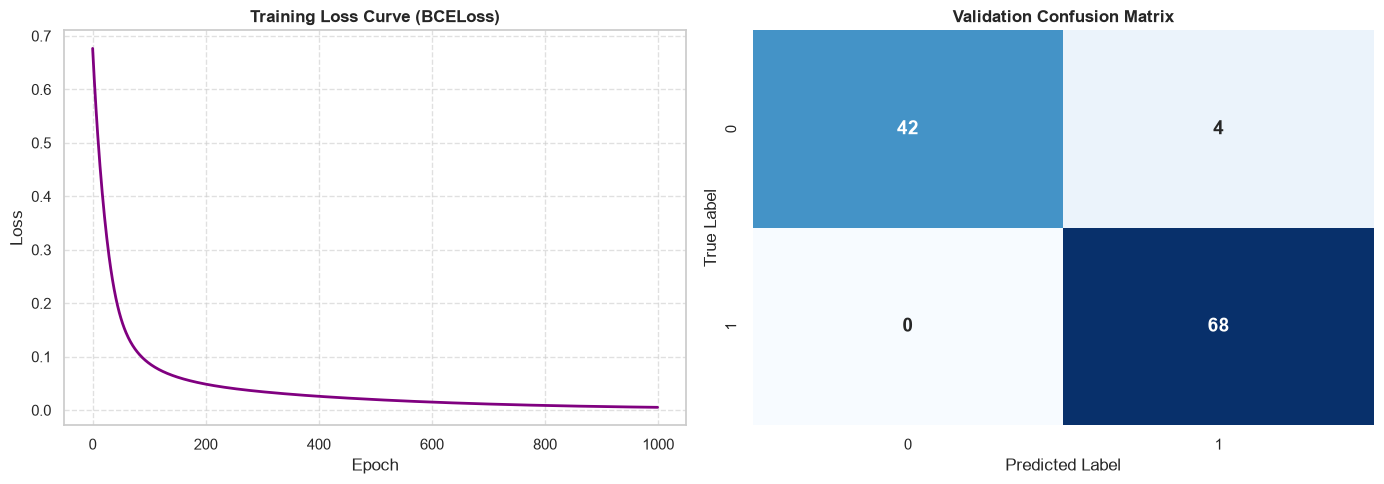

In [258]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import confusion_matrix, classification_report

#data
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
tr_x, val_x, tr_y, val_y = train_test_split(X, y, test_size=0.2)

tensor_tr_x = torch.tensor(tr_x, dtype=torch.float32)
tensor_tr_y = torch.tensor(tr_y, dtype=torch.float32).unsqueeze(dim=1)
tensor_val_x = torch.tensor(val_x, dtype=torch.float32)

model = MLPForBC(30, 90, 1, 1000, 0.001)
model.fit(tensor_tr_x, tensor_tr_y)
pred = model.predict(tensor_val_x)

evaluate_binary_classifier(model, tensor_val_x, val_y)
